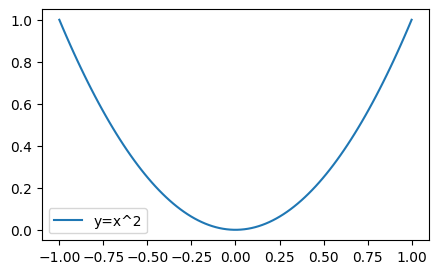

In [2]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-1, 1, 100)
y = x**2

plt.figure(figsize= (5, 3))
plt.plot(x, y, label='y=x^2')
plt.legend()
plt.show()

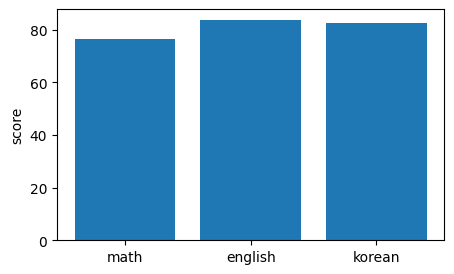

In [3]:
import numpy as np
import matplotlib.pyplot as plt

math = np.array([75, 89, 75, 65, 79])
english = np.array([85, 80, 90, 75, 88])
korean = np.array([72, 90, 70, 88, 93])
x = ['math', 'english', 'korean']

plt.figure(figsize=(5, 3))
plt.bar(x, [np.mean(math), np.mean(english), np.mean(korean)])
plt.ylabel('score')
plt.show()

In [6]:
# -*- coding: utf-8 -*-
# 실습 8. 조건으로 골라내기
import numpy as np                      # [NumPy] 라이브러리 불러오기

score = np.array([55, 82, 67, 90, 45, 73])
print('score =', score)

print('-- (1) 조건 -> 마스크 --')
mask = score >= 70                      # [NumPy] 비교 결과는 True/False 배열(마스크)
print(mask)

print('-- (2) 불리언 인덱싱 --')
print(score[mask])                      # [NumPy] 마스크가 True인 위치의 값만 선택
print(score[score < 60])                # 조건을 바로 써도 된다

print('-- (3) 개수와 비율 --')
print('70점 이상 인원:', np.sum(score >= 70))     # [NumPy] True는 1로 계산 -> 개수
print('70점 이상 비율:', np.mean(score >= 70))    # 평균 = 비율

print('-- (4) np.where --')
result = np.where(score >= 70, '합격', '불합격')    # [NumPy] where(조건, 참일 때 값, 거짓일 때 값)
print(result)
curved = np.where(score < 60, 60, score)           # 60점 미만은 60점으로 올려준다 (최저 60점)
print(curved)

print('-- (5) 조건 결합 --')
mid = score[(score >= 60) & (score < 80)]          # [NumPy] & : 그리고 (각 조건에 괄호)
print('60~79점:', mid)
edge = score[(score < 50) | (score >= 90)]         # [NumPy] | : 또는
print('50 미만 또는 90 이상:', edge)

print('-- (6) any / all --')
print(np.any(score >= 90))              # [NumPy] any(): 하나라도 True 인가?
print(np.all(score >= 60))              # [NumPy] all(): 모두 True 인가?


score = [55 82 67 90 45 73]
-- (1) 조건 -> 마스크 --
[False  True False  True False  True]
-- (2) 불리언 인덱싱 --
[82 90 73]
[55 45]
-- (3) 개수와 비율 --
70점 이상 인원: 3
70점 이상 비율: 0.5
-- (4) np.where --
['불합격' '합격' '불합격' '합격' '불합격' '합격']
[60 82 67 90 60 73]
-- (5) 조건 결합 --
60~79점: [67 73]
50 미만 또는 90 이상: [90 45]
-- (6) any / all --
True
False


In [7]:
# -*- coding: utf-8 -*-
# 실습 10. 종합 실습: 성적 데이터 분석
import numpy as np                      # [NumPy] 라이브러리 불러오기

print('-- (1) 데이터 준비 --')
names = np.array(['민수', '지연', '철수', '영희', '준호'])    # [NumPy] 이름 배열 (문자열도 가능)
subjects = ['국어', '영어', '수학']
scores = np.array([[85, 90, 78],
                   [92, 88, 95],
                   [58, 72, 64],
                   [76, 55, 81],
                   [88, 94, 90]])       # [NumPy] 5명 x 3과목 2차원 배열
print('shape:', scores.shape)           # [NumPy] shape: (5, 3)

print('-- (2) 과목별 분석 (axis=0) --')
print('과목별 평균:', np.round(np.mean(scores, axis=0), 1))   # [NumPy] axis=0: 과목(열)마다
print('과목별 최고:', np.max(scores, axis=0))
print('과목별 최저:', np.min(scores, axis=0))
print('수학 점수만:', scores[:, 2])      # [NumPy] m[:, 열]: 한 열 전체

print('-- (3) 학생별 분석 (axis=1) --')
total = np.sum(scores, axis=1)          # [NumPy] axis=1: 학생(행)마다 합계
avg = np.round(np.mean(scores, axis=1), 1)   # [NumPy] 학생별 평균
for i in range(len(names)):
    print(names[i], '총점', total[i], '평균', avg[i])
best = np.argmax(total)                 # [NumPy] argmax(): 총점이 가장 큰 학생의 위치
print('1등:', names[best], total[best], '점')

print('-- (4) 조건 분석 --')
print('전체 평균:', np.round(np.mean(scores), 1))
print('평균 이상 학생:', names[avg >= np.mean(scores)])      # [NumPy] 불리언 인덱싱
print('과목별 60점 미만 인원:', np.sum(scores < 60, axis=0))   # [NumPy] 조건 개수 + axis

print('-- (5) 학점 매기기 --')
grade = np.where(avg >= 90, 'A',
         np.where(avg >= 80, 'B',
          np.where(avg >= 70, 'C', 'D')))     # [NumPy] where를 겹쳐서 여러 등급 만들기
for n, a, g in zip(names, avg, grade):
    print(n, a, g)


-- (1) 데이터 준비 --
shape: (5, 3)
-- (2) 과목별 분석 (axis=0) --
과목별 평균: [79.8 79.8 81.6]
과목별 최고: [92 94 95]
과목별 최저: [58 55 64]
수학 점수만: [78 95 64 81 90]
-- (3) 학생별 분석 (axis=1) --
민수 총점 253 평균 84.3
지연 총점 275 평균 91.7
철수 총점 194 평균 64.7
영희 총점 212 평균 70.7
준호 총점 272 평균 90.7
1등: 지연 275 점
-- (4) 조건 분석 --
전체 평균: 80.4
평균 이상 학생: ['민수' '지연' '준호']
과목별 60점 미만 인원: [1 1 0]
-- (5) 학점 매기기 --
민수 84.3 B
지연 91.7 A
철수 64.7 D
영희 70.7 C
준호 90.7 A
